In [1]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

torch.manual_seed(42)

X = torch.linspace(-2,2,120).unsqueeze(1)
y = X ** 2 + 0.25 * torch.randn_like(X)

indices = torch.randperm(len(X))

train_idx = indices[:84]
val_idx = indices[84:102]
test_idx = indices[102:]

X_train, y_train = X[train_idx], y[train_idx]
X_val, y_val = X[val_idx], y[val_idx]
X_test, y_test = X[test_idx], y[test_idx]

print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

Train: torch.Size([84, 1])
Validation: torch.Size([18, 1])
Test: torch.Size([18, 1])


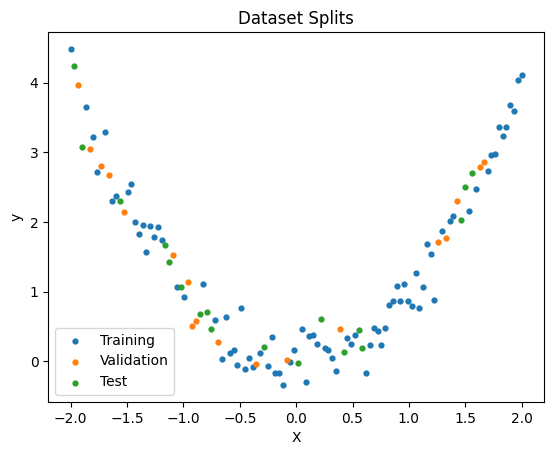

In [2]:
plt.scatter(X_train, y_train, label="Training", s=12)
plt.scatter(X_val, y_val, label="Validation", s=12)
plt.scatter(X_test, y_test, label="Test", s=12)

plt.xlabel("X")
plt.ylabel("y")
plt.title("Dataset Splits")
plt.legend()
plt.show()

In [3]:
model = nn.Sequential(
    nn.Linear(1, 32),
    nn.ReLU(),
    nn.Linear(32, 1)
)

loss_fn = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

train_losses = []
val_losses = []

for epoch in range(500):
    model.train()

    prediction = model(X_train)
    train_loss = loss_fn(prediction, y_train)

    optimizer.zero_grad()
    train_loss.backward()
    optimizer.step()

    model.eval()

    with torch.no_grad():
        val_prediction = model(X_val)
        val_loss = loss_fn(val_prediction, y_val)

    train_losses.append(train_loss.item())
    val_losses.append(val_loss.item())

print("Training MSE:", train_losses[-1])
print("Validation MSE:", val_losses[-1])

Training MSE: 0.06012217327952385
Validation MSE: 0.05234195664525032


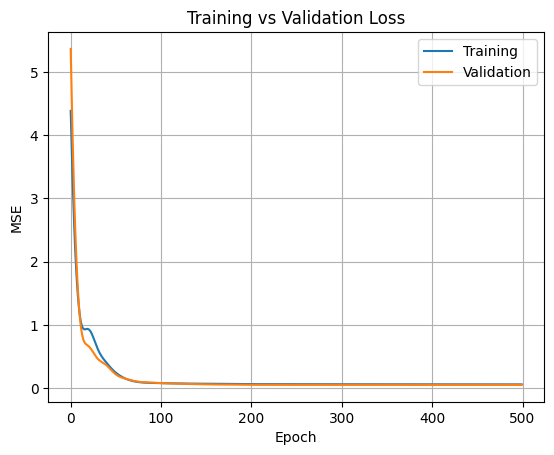

In [4]:
plt.plot(train_losses, label="Training")
plt.plot(val_losses, label="Validation")

plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("Training vs Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

In [5]:
model.eval()

with torch.no_grad():
    test_prediction = model(X_test)
    test_loss = loss_fn(test_prediction, y_test)

print("Training MSE:", train_losses[-1])
print("Validation MSE:", val_losses[-1])
print("Test MSE:", test_loss.item())

Training MSE: 0.06012217327952385
Validation MSE: 0.05234195664525032
Test MSE: 0.05746752768754959


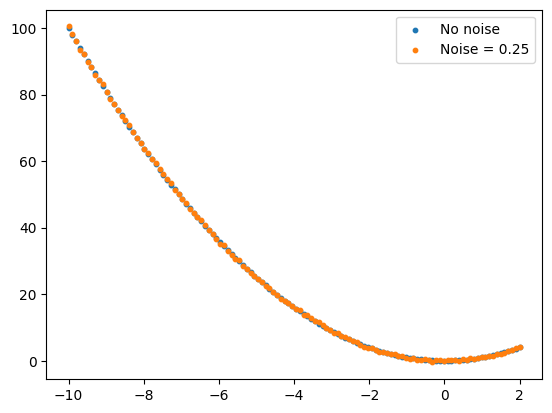

In [6]:
torch.manual_seed(42)

X = torch.linspace(-10, 2, 120).unsqueeze(1)

plt.scatter(X, X**2, label="No noise", s=10)
plt.scatter(X, X**2 + 0.25 * torch.randn_like(X),
            label="Noise = 0.25", s=10)

plt.legend()
plt.show()

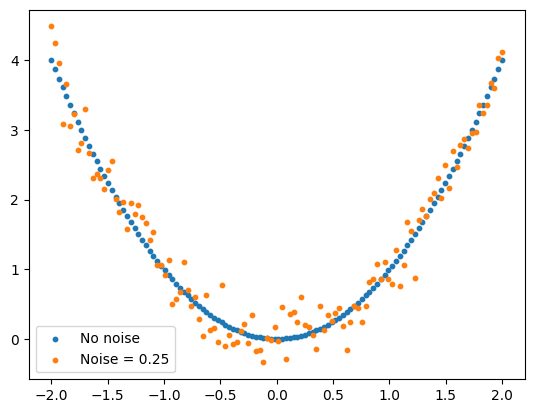

In [7]:
torch.manual_seed(42)

X = torch.linspace(-2, 2, 120).unsqueeze(1)

plt.scatter(X, X**2, label="No noise", s=10)
plt.scatter(X, X**2 + 0.25 * torch.randn_like(X),
            label="Noise = 0.25", s=10)

plt.legend()
plt.show()